# Titanic Survival Prediction: A Simple Predictive Model with Scikit-learn

**Month 2, Data Science | Task 2: Build a Simple Predictive Model**

**Objective:** Predict whether a passenger survived the Titanic disaster (`Survived`: 0 or 1) from the other columns in the dataset.

**Plan**
1. Load and explore the data
2. Preprocess (missing values, categorical encoding, a few engineered features)
3. Split into training and testing sets
4. Train two models: Logistic Regression and Decision Tree
5. Evaluate with accuracy, precision, recall, F1, ROC-AUC, MSE and R2
6. Interpret the results and document conclusions


## 1. Setup and Data Loading

In [1]:
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay,
                             mean_squared_error, r2_score, classification_report)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
FIG = "../images/"

df = pd.read_csv("../dataset/Titanic-Dataset.csv")
print("Shape:", df.shape)
df.head()

Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Data Exploration

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [3]:
# Missing values
missing = pd.DataFrame({"missing": df.isna().sum(), "percent": (df.isna().mean() * 100).round(1)})
missing[missing.missing > 0].sort_values("missing", ascending=False)

,missing,percent
Cabin,687,77.1
Age,177,19.9
Embarked,2,0.2


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


In [5]:
print(df["Survived"].value_counts())
print()
print((df["Survived"].value_counts(normalize=True) * 100).round(1))

Survived
0    549
1    342
Name: count, dtype: int64

Survived
0    61.6
1    38.4
Name: proportion, dtype: float64


About 38% of passengers survived, so the classes are moderately imbalanced. A model that always predicts "did not survive" would already score about 62% accuracy. That number is the baseline any real model has to beat.

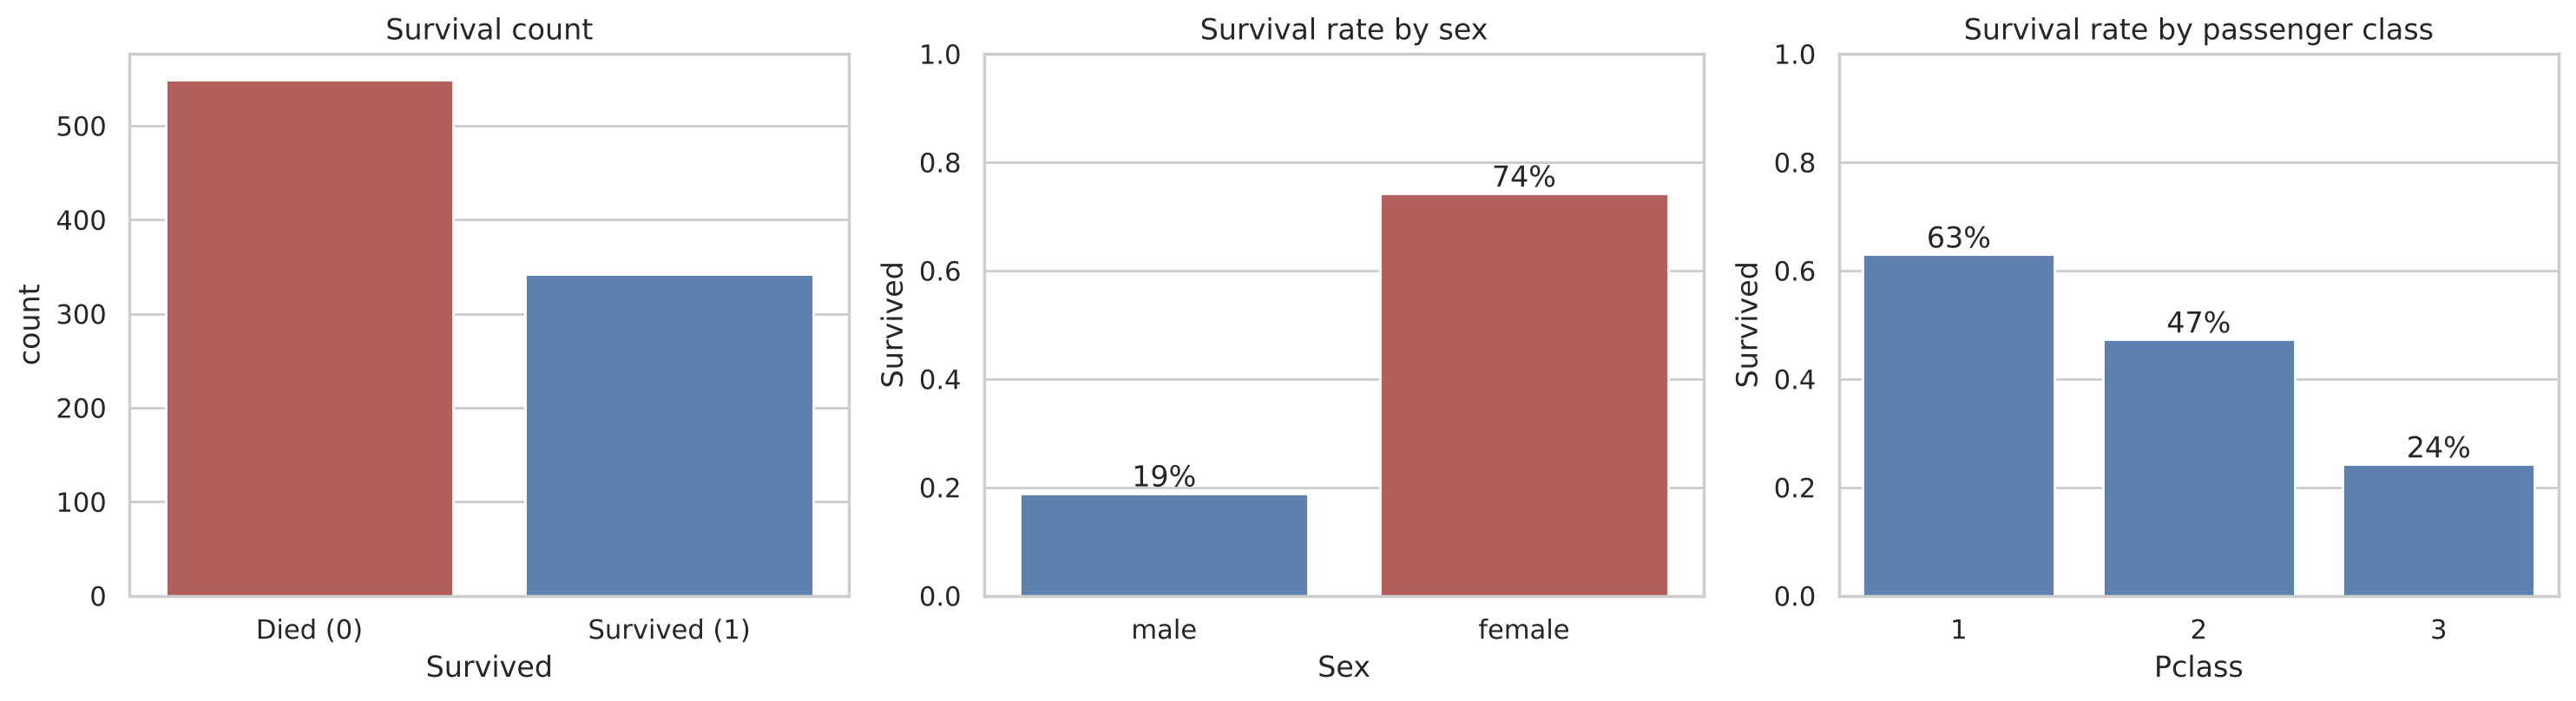

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
sns.countplot(data=df, x="Survived", ax=ax[0], palette=["#c0504d", "#4f81bd"])
ax[0].set_title("Survival count"); ax[0].set_xticklabels(["Died (0)", "Survived (1)"])

sns.barplot(data=df, x="Sex", y="Survived", ax=ax[1], palette=["#4f81bd", "#c0504d"], errorbar=None)
ax[1].set_title("Survival rate by sex"); ax[1].set_ylim(0, 1)
for p in ax[1].patches: ax[1].annotate(f"{p.get_height():.0%}", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")

sns.barplot(data=df, x="Pclass", y="Survived", ax=ax[2], color="#4f81bd", errorbar=None)
ax[2].set_title("Survival rate by passenger class"); ax[2].set_ylim(0, 1)
for p in ax[2].patches: ax[2].annotate(f"{p.get_height():.0%}", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.tight_layout(); plt.savefig(FIG+"01_survival_overview.png", dpi=150); plt.show()

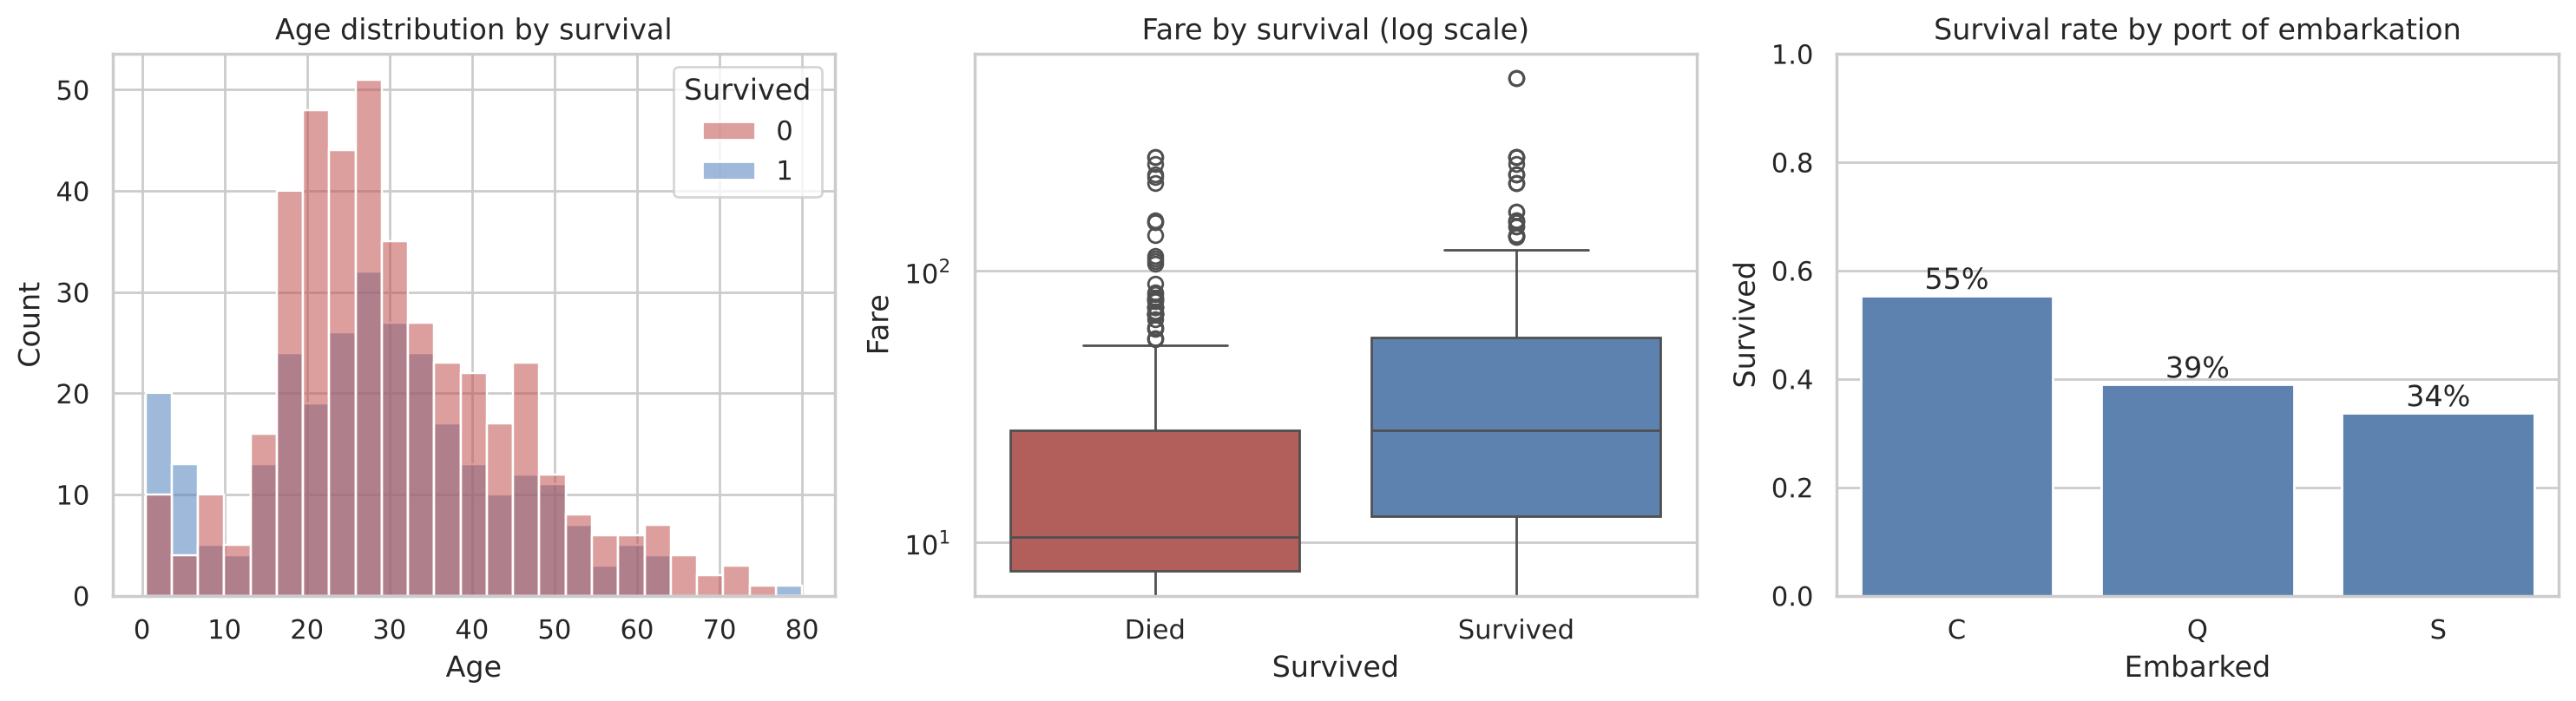

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
sns.histplot(data=df, x="Age", hue="Survived", bins=25, kde=False, multiple="layer", alpha=0.55, ax=ax[0], palette=["#c0504d", "#4f81bd"])
ax[0].set_title("Age distribution by survival")

sns.boxplot(data=df, x="Survived", y="Fare", ax=ax[1], palette=["#c0504d", "#4f81bd"])
ax[1].set_yscale("log"); ax[1].set_title("Fare by survival (log scale)")
ax[1].set_xticklabels(["Died", "Survived"])

sns.barplot(data=df, x="Embarked", y="Survived", ax=ax[2], color="#4f81bd", errorbar=None, order=["C", "Q", "S"])
ax[2].set_title("Survival rate by port of embarkation"); ax[2].set_ylim(0, 1)
for p in ax[2].patches: ax[2].annotate(f"{p.get_height():.0%}", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.tight_layout(); plt.savefig(FIG+"02_age_fare_embarked.png", dpi=150); plt.show()

Pclass      1      2      3
Sex                        
female  0.968  0.921  0.500
male    0.369  0.157  0.135


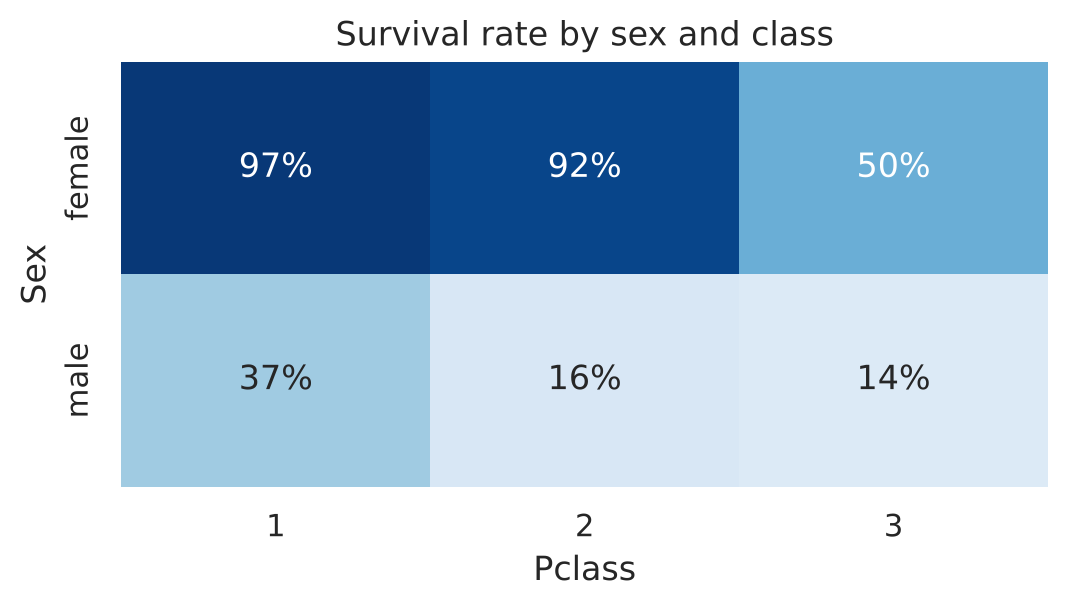

In [8]:
# Sex x Class together
pivot = df.pivot_table(values="Survived", index="Sex", columns="Pclass", aggfunc="mean").round(3)
print(pivot)
plt.figure(figsize=(5.5, 3.2))
sns.heatmap(pivot, annot=True, fmt=".0%", cmap="Blues", cbar=False, vmin=0, vmax=1)
plt.title("Survival rate by sex and class"); plt.tight_layout()
plt.savefig(FIG+"03_sex_class_heatmap.png", dpi=150); plt.show()

**What the exploration shows**
- Sex is the strongest single signal: women survived at roughly 74%, men at roughly 19%.
- Passenger class matters a lot: first class survived at about 63%, third class at about 24%.
- The combination is even sharper: almost all first and second class women survived, while third class men had the lowest rate.
- Fare behaves like a proxy for class: survivors paid noticeably more.
- Age is missing for 177 rows, Cabin for 687 (77%) and Embarked for just 2.

## 3. Preprocessing

### 3.1 Decisions on columns

| Column | Decision | Reason |
|---|---|---|
| PassengerId | Drop | Row identifier, no predictive meaning |
| Ticket | Drop | 681 unique values out of 891, no usable pattern without heavy cleaning |
| Name | Use only to extract `Title` | The title (Mr, Mrs, Miss, Master) carries age, sex and status information |
| Cabin | Convert to `HasCabin` flag | 77% missing, but whether a cabin was recorded is itself informative (mostly upper-class passengers) |
| SibSp + Parch | Combine to `FamilySize` | Both describe family aboard, together they are cleaner |
| Fare | Add `LogFare` | Fare is heavily right skewed, a log transform helps the linear model |
| Age | Impute with median | 20% missing, median is robust to outliers |
| Embarked | Impute with most frequent | Only 2 missing |
| Sex, Embarked, Title, Pclass | One-hot encode | Models need numeric input |

In [9]:
data = df.copy()

# Title from Name, grouped into 5 buckets
data["Title"] = data["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
data["Title"] = data["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
common = ["Mr", "Mrs", "Miss", "Master"]
data["Title"] = np.where(data["Title"].isin(common), data["Title"], "Rare")

data["FamilySize"] = data["SibSp"] + data["Parch"] + 1
data["HasCabin"] = data["Cabin"].notna().astype(int)
data["LogFare"] = np.log1p(data["Fare"])

print(data["Title"].value_counts())
print()
print(data.groupby("Title")["Survived"].mean().round(3))

Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64

Title
Master    0.575
Miss      0.703
Mr        0.157
Mrs       0.794
Rare      0.348
Name: Survived, dtype: float64


In [10]:
num_features = ["Age", "LogFare", "FamilySize", "HasCabin"]
cat_features = ["Pclass", "Sex", "Embarked", "Title"]
features = num_features + cat_features
target = "Survived"

X = data[features].copy()
X["Pclass"] = X["Pclass"].astype(str)   # treat class as a category, not a number
y = data[target]
print(X.shape, y.shape)
X.head()

(891, 8) (891,)


,Age,LogFare,FamilySize,HasCabin,Pclass,Sex,Embarked,Title
0,22.0,2.110213,2,0,3,male,S,Mr
1,38.0,4.280593,2,1,1,female,C,Mrs
2,26.0,2.188856,1,0,3,female,S,Miss
3,35.0,3.990834,2,1,1,female,S,Mrs
4,35.0,2.202765,1,0,3,male,S,Mr


### 3.2 Train/test split

An 80/20 split, stratified on the target so both sets keep the same survival ratio. The split happens **before** any imputation or scaling is fitted. Imputation values (the Age median, the most common port) are learned from the training set only and then applied to the test set. That prevents information from the test set leaking into training.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Survival rate train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))
print("Missing Age in train:", X_train["Age"].isna().sum(), "| test:", X_test["Age"].isna().sum())

Train: (712, 8) | Test: (179, 8)
Survival rate train: 0.383 | test: 0.385
Missing Age in train: 137 | test: 40


### 3.3 Preprocessing pipeline

Two versions are needed. Logistic Regression is sensitive to feature scale, so it gets standardised numeric inputs. Decision Trees split on thresholds and do not care about scale, so scaling is skipped for them (it would not hurt, but it is unnecessary).

In [12]:
cat_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(drop=None, handle_unknown="ignore", sparse_output=False)),
])

prep_lr = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_features),
    ("cat", cat_pipe, cat_features),
])
prep_dt = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_features),
    ("cat", cat_pipe, cat_features),
])

# sanity check: no missing values after preprocessing
Xt = prep_lr.fit(X_train).transform(X_train)
print("Transformed train shape:", Xt.shape, "| NaNs left:", int(np.isnan(Xt).sum()))
print("Age median learned from train:", prep_lr.named_transformers_["num"].named_steps["impute"].statistics_[0])

Transformed train shape: (712, 17) | NaNs left: 0
Age median learned from train: 28.5


## 4. Model Training

### 4.1 Baseline

A dummy classifier that always predicts the majority class. Anything useful has to beat this.

In [13]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
dummy_acc = accuracy_score(y_test, dummy.predict(X_test))
print(f"Baseline (always predict 'died') accuracy: {dummy_acc:.4f}")

Baseline (always predict 'died') accuracy: 0.6145


### 4.2 Logistic Regression

The natural first choice for a yes/no outcome. It is fast, stable and its coefficients can be read directly.

In [14]:
lr = Pipeline([("prep", prep_lr), ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))])
lr.fit(X_train, y_train)
print("Logistic Regression trained.")

Logistic Regression trained.


### 4.3 Decision Tree

I train it twice on purpose. First with default settings (the tree can grow until it memorises the training data), then with `max_depth`, `min_samples_leaf` and `criterion` tuned by 5-fold cross-validation on the training set. The comparison shows overfitting clearly.

In [15]:
dt_default = Pipeline([("prep", prep_dt), ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))])
dt_default.fit(X_train, y_train)

param_grid = {
    "model__max_depth": [2, 3, 4, 5, 6, 8],
    "model__min_samples_leaf": [1, 5, 10, 20],
    "model__criterion": ["gini", "entropy"],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(
    Pipeline([("prep", prep_dt), ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
    param_grid, cv=cv, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)
dt_tuned = grid.best_estimator_

print("Best params:", grid.best_params_)
print(f"Best CV accuracy (train folds): {grid.best_score_:.4f}")
print("Default tree depth:", dt_default.named_steps["model"].get_depth(),
      "| leaves:", dt_default.named_steps["model"].get_n_leaves())

Best params: {'model__criterion': 'gini', 'model__max_depth': 3, 'model__min_samples_leaf': 1}
Best CV accuracy (train folds): 0.8216
Default tree depth: 22 | leaves: 163


## 5. Evaluation

In [16]:
def evaluate(name, model):
    pred_tr = model.predict(X_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    return {
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, pred_tr),
        "Test Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
        "MSE (probabilities)": mean_squared_error(y_test, proba),
        "R2 (probabilities)": r2_score(y_test, proba),
    }

models = {
    "Logistic Regression": lr,
    "Decision Tree (default)": dt_default,
    "Decision Tree (tuned)": dt_tuned,
}
results = pd.DataFrame([evaluate(n, m) for n, m in models.items()]).set_index("Model")
results.round(4)

,Train Accuracy,Test Accuracy,Precision,Recall,F1,ROC-AUC,MSE (probabilities),R2 (probabilities)
Model,,,,,,,,
Logistic Regression,0.8244,0.8268,0.7879,0.7536,0.7704,0.8660,0.1319,0.4433
Decision Tree (default),0.9874,0.7933,0.7353,0.7246,0.7299,0.7702,0.2120,0.1051
Decision Tree (tuned),0.8315,0.8324,0.8197,0.7246,0.7692,0.8530,0.1306,0.4488


### 5.1 A note on MSE and R2

The brief lists MSE and R2 "as applicable". Both are regression metrics. For a classifier they only make sense if computed on predicted **probabilities**, and then:
- MSE on probabilities is the **Brier score** (lower is better, 0.25 is what you get by always guessing 50%).
- R2 on probabilities says how much better the probabilities are than predicting the average survival rate for everyone.

MSE computed on hard 0/1 labels is just `1 - accuracy`, so it adds nothing. I report the probability versions for completeness, but accuracy, F1 and ROC-AUC are the metrics to judge this model by.

In [17]:
print(classification_report(y_test, lr.predict(X_test), target_names=["Died", "Survived"]))
print("-----  Tuned Decision Tree  -----")
print(classification_report(y_test, dt_tuned.predict(X_test), target_names=["Died", "Survived"]))

              precision    recall  f1-score   support

        Died       0.85      0.87      0.86       110
    Survived       0.79      0.75      0.77        69

    accuracy                           0.83       179
   macro avg       0.82      0.81      0.82       179
weighted avg       0.83      0.83      0.83       179

-----  Tuned Decision Tree  -----
              precision    recall  f1-score   support

        Died       0.84      0.90      0.87       110
    Survived       0.82      0.72      0.77        69

    accuracy                           0.83       179
   macro avg       0.83      0.81      0.82       179
weighted avg       0.83      0.83      0.83       179



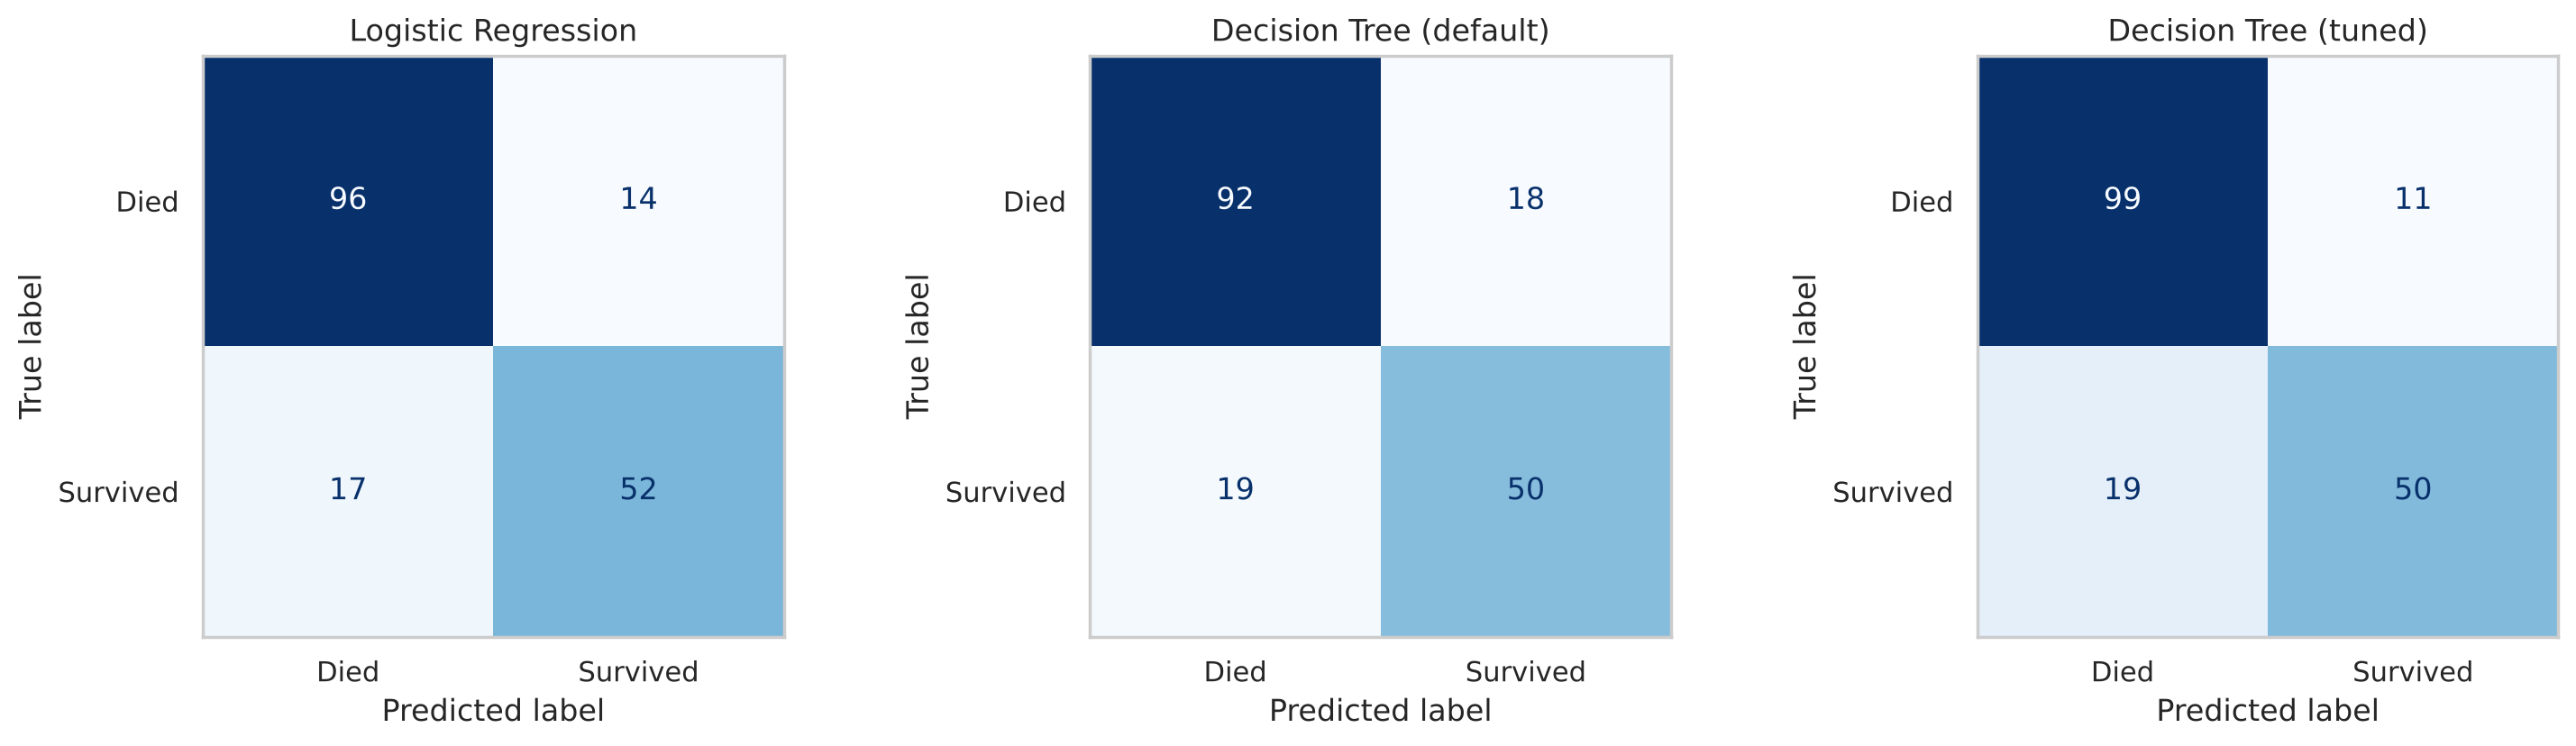

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for a, (name, m) in zip(ax, models.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, m.predict(X_test)),
                           display_labels=["Died", "Survived"]).plot(ax=a, cmap="Blues", colorbar=False)
    a.set_title(name); a.grid(False)
plt.tight_layout(); plt.savefig(FIG+"04_confusion_matrices.png", dpi=150); plt.show()

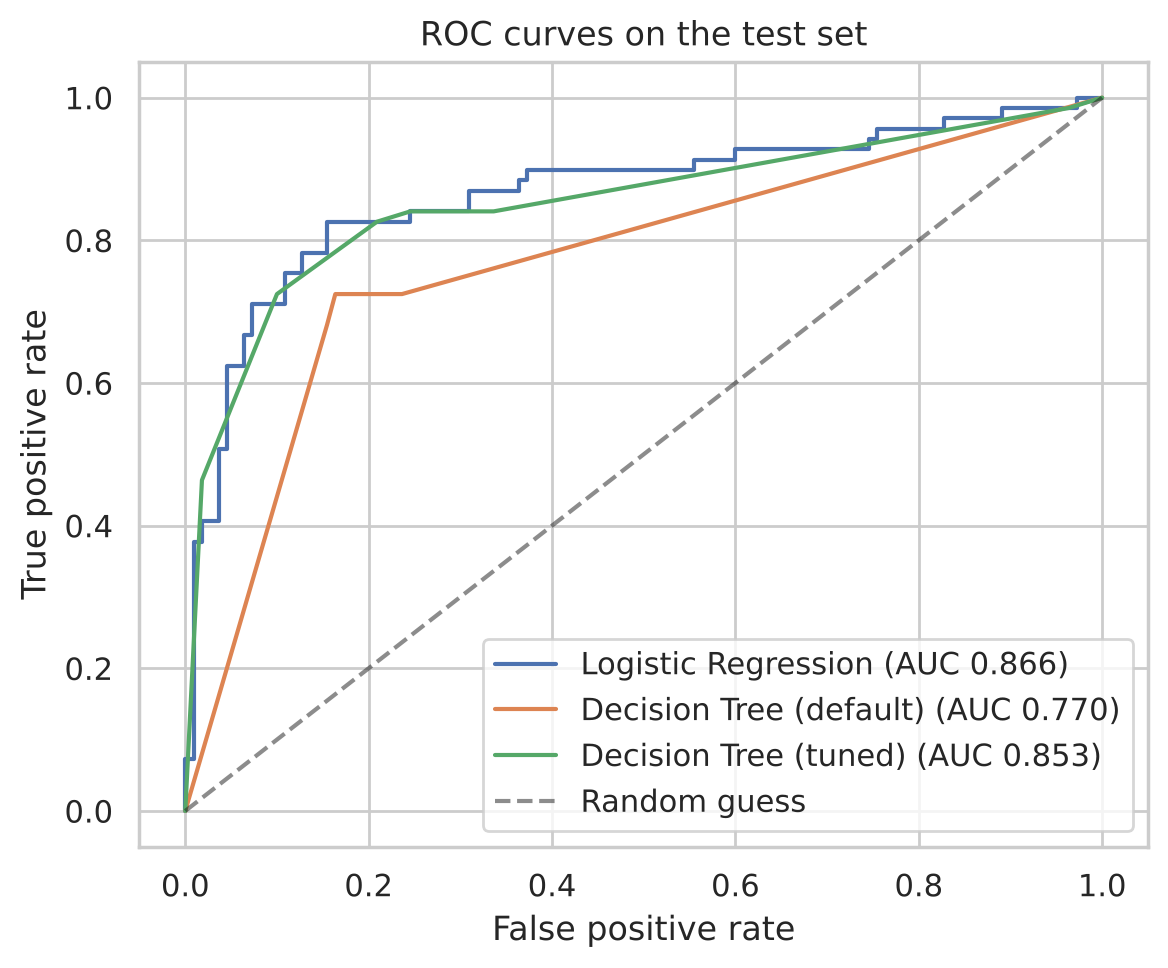

In [19]:
plt.figure(figsize=(6, 5))
for name, m in models.items():
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, m.predict_proba(X_test)[:,1]):.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.5, label="Random guess")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("ROC curves on the test set")
plt.legend(loc="lower right"); plt.tight_layout(); plt.savefig(FIG+"05_roc_curves.png", dpi=150); plt.show()

### 5.2 Cross-validation: is the test score a fluke?

With only 179 test passengers, one lucky or unlucky split can move accuracy by a few points. Running 5-fold cross-validation on the full dataset gives a steadier picture.

In [20]:
full_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
best_params = {k.replace("model__", ""): v for k, v in grid.best_params_.items()}
cv_models = {
    "Logistic Regression": Pipeline([("prep", prep_lr), ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
    "Decision Tree (tuned)": Pipeline([("prep", prep_dt), ("model", DecisionTreeClassifier(random_state=RANDOM_STATE, **best_params))]),
}
cv_rows = {}
for name, m in cv_models.items():
    s = cross_val_score(m, X, y, cv=full_cv, scoring="accuracy")
    cv_rows[name] = {"mean": s.mean(), "std": s.std(), "folds": s.round(4).tolist()}
    print(f"{name}: mean {s.mean():.4f}, std {s.std():.4f}, folds {s.round(3)}")

Logistic Regression: mean 0.8249, std 0.0146, folds [0.844 0.815 0.803 0.837 0.826]
Decision Tree (tuned): mean 0.8159, std 0.0201, folds [0.832 0.82  0.781 0.809 0.837]


## 6. Interpreting the Models

### 6.1 Logistic Regression coefficients

Coefficients are on the log-odds scale. Exponentiating them gives odds ratios: a value above 1 raises the odds of survival, below 1 lowers them. Numeric features were standardised, so their ratios describe the effect of a one standard deviation change.

,coefficient,odds_ratio
Title_Master,1.218,3.379
Sex_female,0.836,2.308
Title_Mrs,0.599,1.820
HasCabin,0.475,1.608
LogFare,0.450,1.569
Embarked_Q,0.331,1.393
Pclass_2,0.269,1.309
Pclass_1,0.264,1.302
Embarked_C,0.041,1.041
Title_Miss,-0.129,0.879


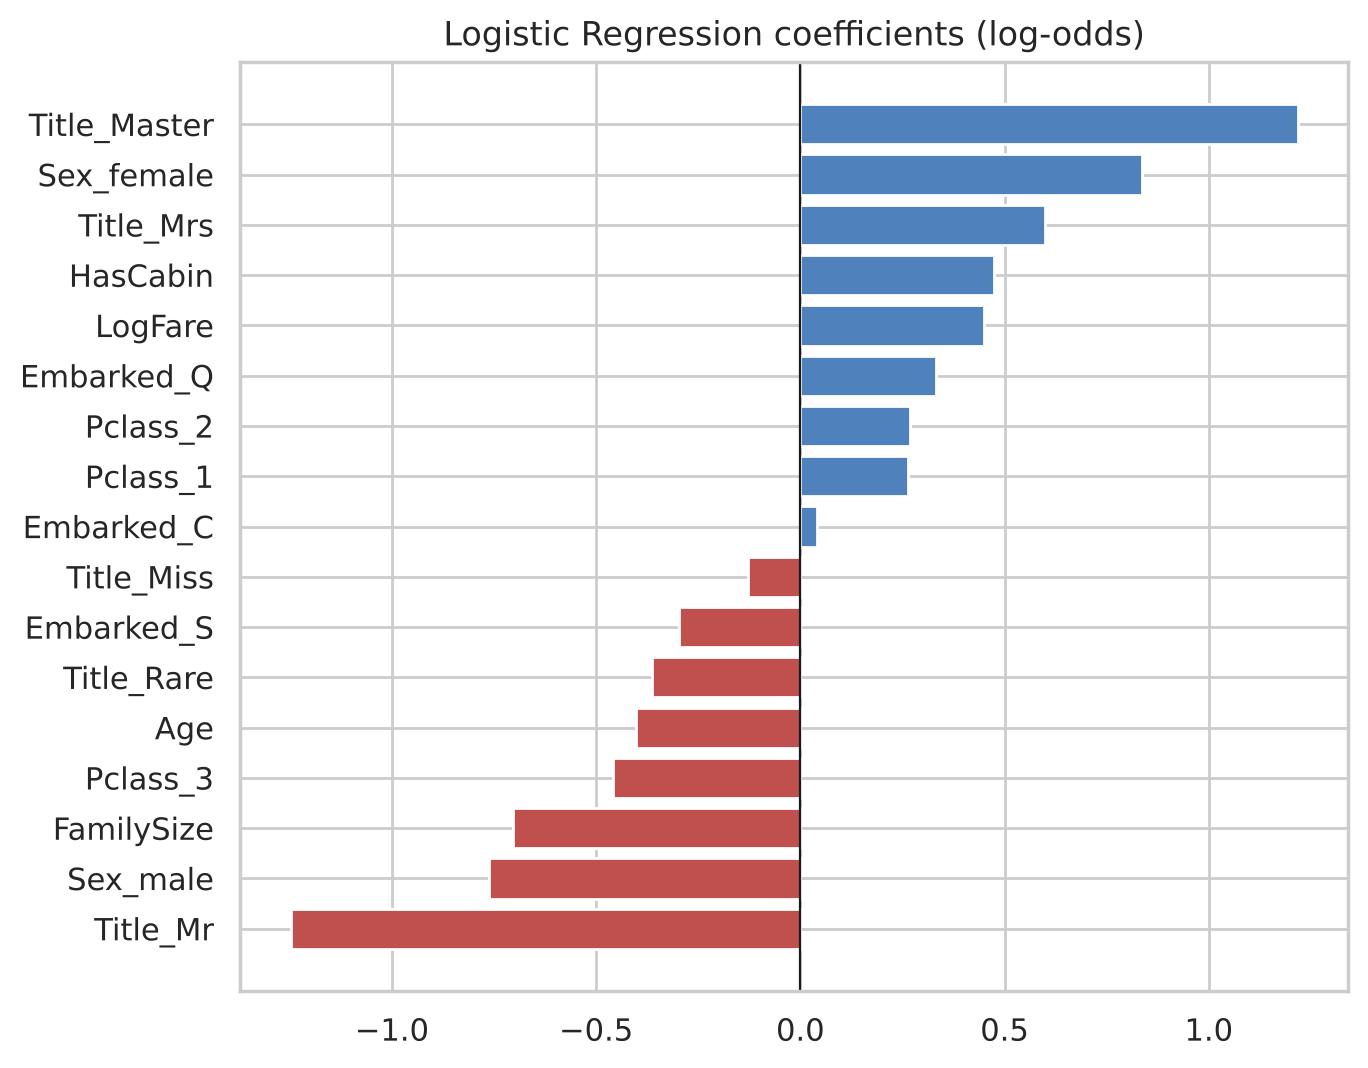

In [21]:
names = lr.named_steps["prep"].get_feature_names_out()
names = [n.replace("num__", "").replace("cat__", "") for n in names]
coefs = pd.Series(lr.named_steps["model"].coef_[0], index=names).sort_values()
odds = np.exp(coefs).round(3)
display(pd.DataFrame({"coefficient": coefs.round(3), "odds_ratio": odds}).sort_values("coefficient", ascending=False))

plt.figure(figsize=(7, 5.5))
colors = ["#c0504d" if c < 0 else "#4f81bd" for c in coefs]
plt.barh(coefs.index, coefs.values, color=colors)
plt.axvline(0, color="k", lw=0.8)
plt.title("Logistic Regression coefficients (log-odds)")
plt.tight_layout(); plt.savefig(FIG+"06_lr_coefficients.png", dpi=150); plt.show()

### 6.2 Decision Tree feature importance and structure

,importance
Title_Mr,0.630
Pclass_3,0.155
FamilySize,0.082
Title_Rare,0.061
HasCabin,0.050
Age,0.013
LogFare,0.008
Pclass_1,0.000
Pclass_2,0.000
Sex_male,0.000


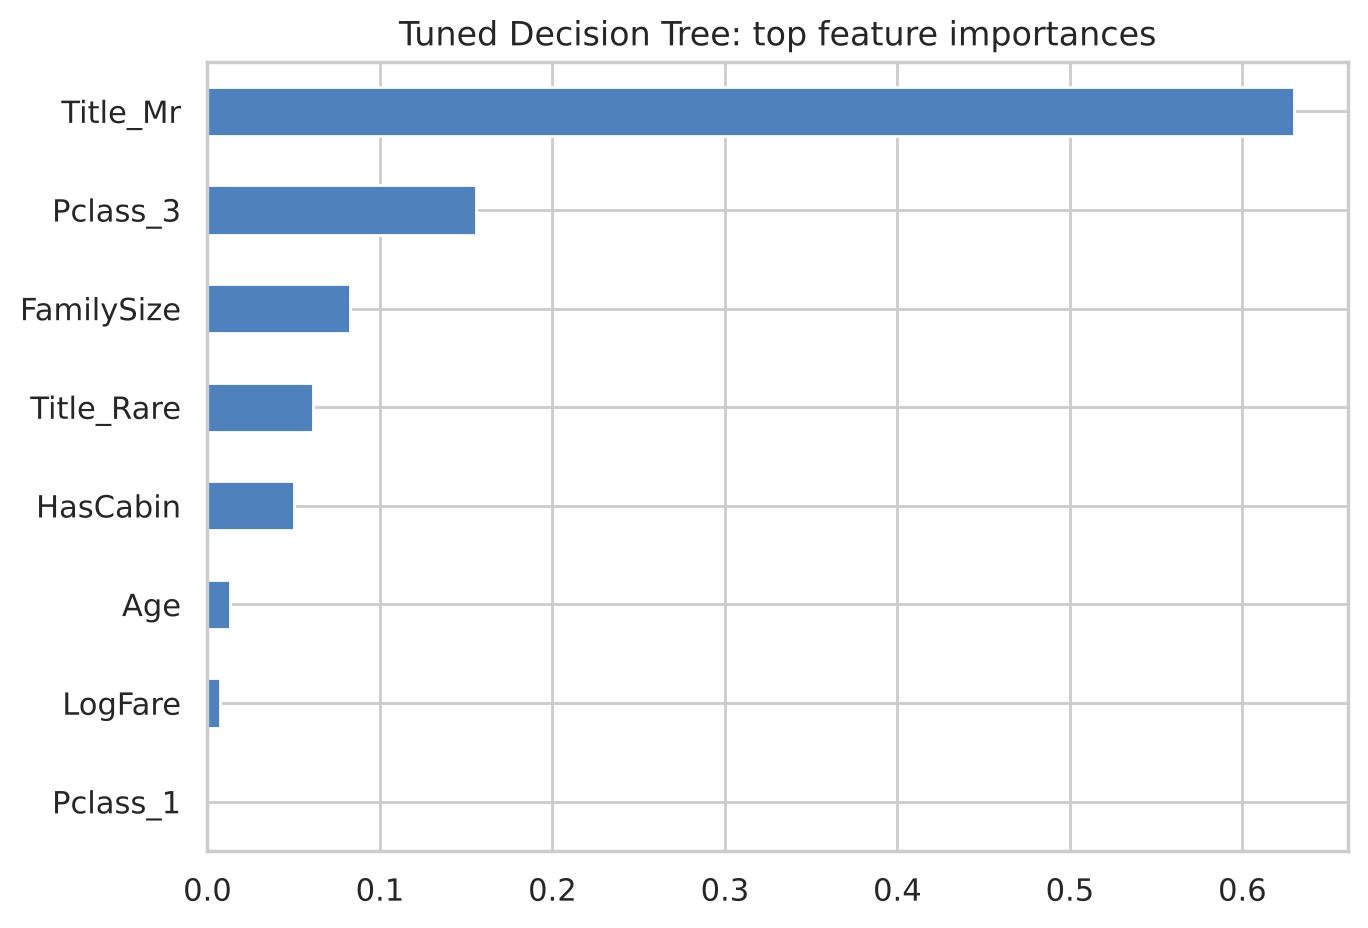

In [22]:
dt_names = [n.replace("num__", "").replace("cat__", "") for n in dt_tuned.named_steps["prep"].get_feature_names_out()]
imp = pd.Series(dt_tuned.named_steps["model"].feature_importances_, index=dt_names).sort_values(ascending=False)
display(imp.round(3).head(10).to_frame("importance"))

plt.figure(figsize=(7, 4.8))
imp.head(8).sort_values().plot.barh(color="#4f81bd")
plt.title("Tuned Decision Tree: top feature importances")
plt.tight_layout(); plt.savefig(FIG+"07_dt_importance.png", dpi=150); plt.show()

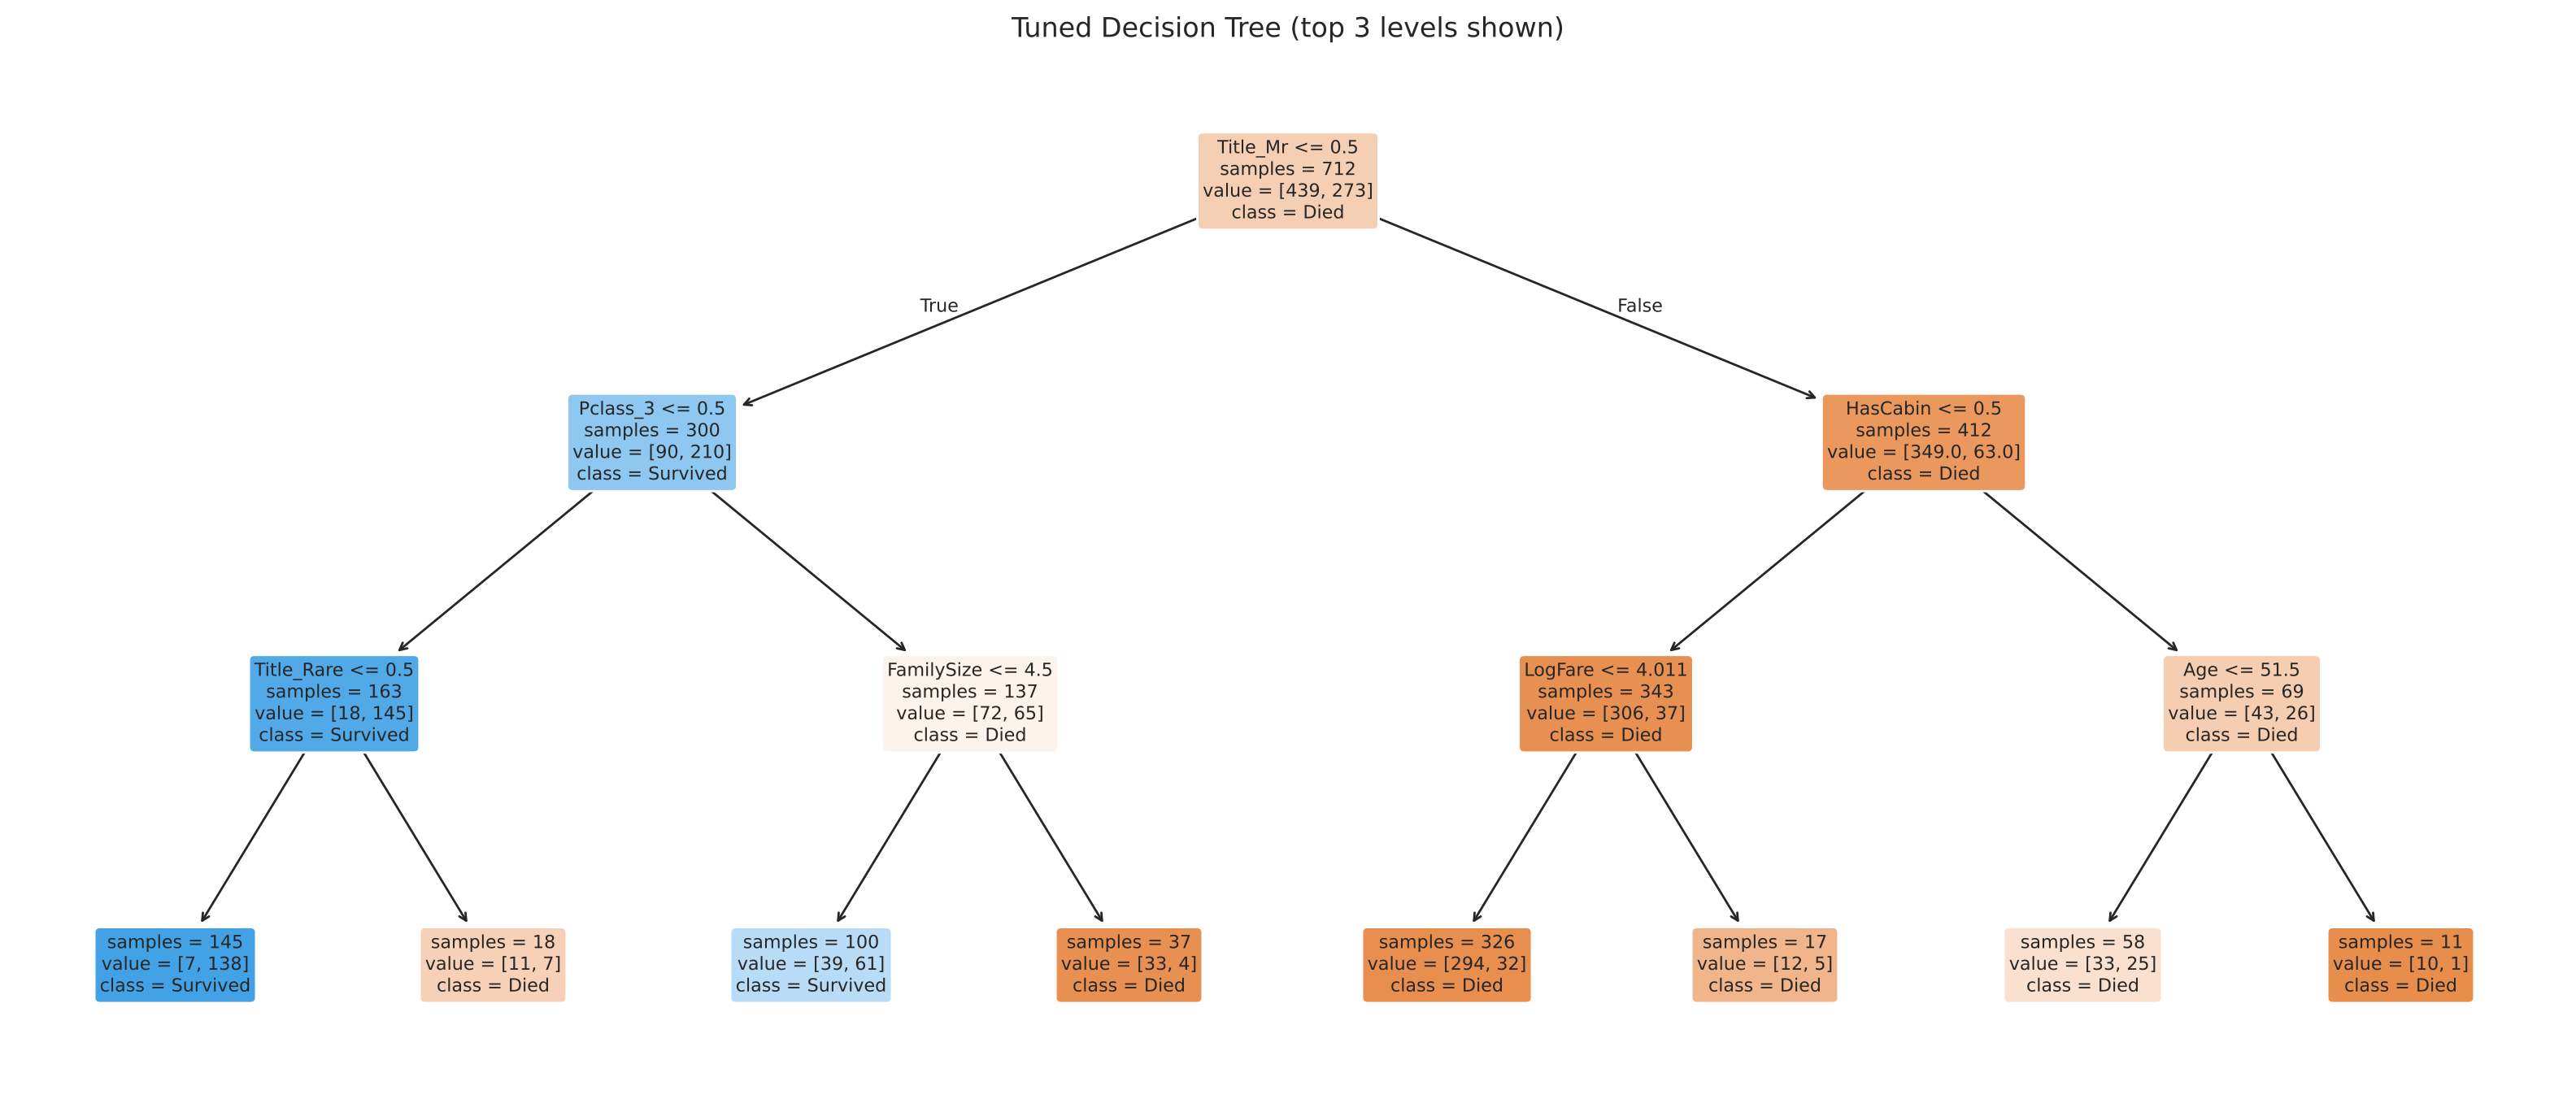

In [23]:
plt.figure(figsize=(16, 7))
plot_tree(dt_tuned.named_steps["model"], feature_names=dt_names, class_names=["Died", "Survived"],
          filled=True, rounded=True, fontsize=8, max_depth=3, impurity=False, proportion=False)
plt.title("Tuned Decision Tree (top 3 levels shown)")
plt.tight_layout(); plt.savefig(FIG+"08_decision_tree.png", dpi=150); plt.show()

## 7. Observations and Conclusions

Key points after running all the cells above (the full write-up is in the PDF report):

1. Both tuned models clearly beat the 61.5% "always predict died" baseline, landing around 83% test accuracy.
2. The untuned Decision Tree memorises the training set (near perfect training accuracy) and loses accuracy on unseen passengers. Limiting its depth fixes most of that.
3. Logistic Regression and the tuned Decision Tree end up close to each other. Logistic Regression is the more stable of the two across cross-validation folds, and its coefficients are easy to explain.
4. Sex, passenger class and title drive almost every prediction, which matches the historical "women and children first" evacuation and the class gap in lifeboat access.

**Limitations**
- Only 891 rows, so test metrics have a wide margin of error.
- Age was imputed with a single median, which blurs real differences (a "Master" is a boy, a "Mr" is an adult man).
- Cabin was reduced to a yes/no flag, losing deck information.
- No Random Forest or boosting was tried, by design, since the task asks for a simple model.
